### **Setup: Imports und Initialisierung**

In [1]:
import sys
import os
import glob
sys.path.append(os.path.abspath('..'))

from quinex_application.scopus_data import ProcessScopusData
from quinex_application.visualisation_metadata import VisualisationMetadata

In [3]:
output_path = "../data/paper/paper_dataset.parquet"
csvs_paths = glob.glob("../data/paper/wos_query4/by_years/wos_*.xls")
query_name = 'Query: AB=("energy system*" AND (simul* OR model* OR plan OR plans OR planning OR optimi* OR analy* OR assess* OR evaluat*))'
query_date = "10.06.2025"
quelle_name = "Source: WOS"

scopus = ProcessScopusData(csvs_paths, output_path, query_name, query_date, quelle_name) 
visualisation = VisualisationMetadata(output_path)

## **Load and Clean CSV Files**

### **Combine the CSV Files**

In [ ]:
df = scopus.combine_csvs()
print(len(df))

### **Clean duplicate DOIs**

In [ ]:
duplicate_doi_values = df["DOI"].value_counts()
duplicate_doi_values = duplicate_doi_values[duplicate_doi_values > 1]
print(f"Anzahl verschiedener mehrfacher DOIs: {len(duplicate_doi_values)}")
print(f"Anzahl an Zeilen mit mehrfacher DOI: {duplicate_doi_values.sum()}")

In [ ]:
df_cleaned = scopus.remove_duplicates_doi()
print(len(df_cleaned))

### **Add new Papers to Parquet**

In [ ]:
# TODO: Funktion weiter testen
parquet = scopus.update_parquet_with_new_data()
display(parquet)

### **Save cleaned and added data**

In [ ]:
df = scopus.save_df()

## **Select specific Query**

In [7]:
#visualisation.load_df(query_name, query_date)
visualisation.load_df('Query: TITLE-ABS-KEY ( ( "energy system*" ) AND ( simul* OR model* OR "plan" OR "plans" OR "planning" OR optimi* OR analy* OR assess* OR evaluat* ) ) AND ( LIMIT-TO ( OA , "all" ) ) AND ( LIMIT-TO ( LANGUAGE , "English" ) )', '14.05.2025')
#display(visualisation.df.head())
print(len(visualisation.df[visualisation.df["Year"].between(2022, 2025)]))

12707


## **Analyse Metadata**

### **Paper pro Jahr**

C:\Users\m.gorres\AppData\Local\Temp\ipykernel_1668\73450831.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


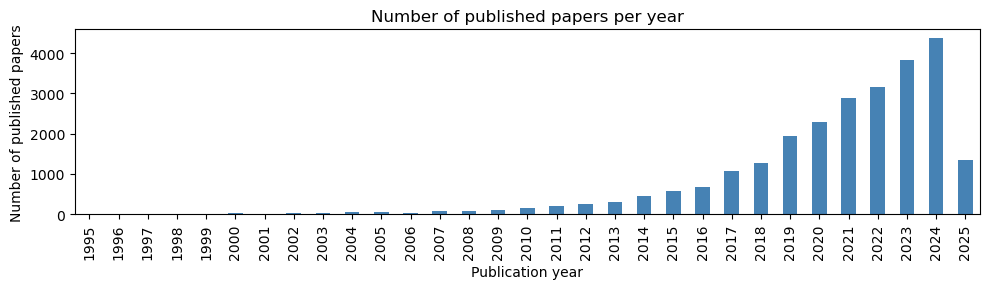

In [5]:
fig = visualisation.paper_per_year(start_year = 1995)
fig.show()

### **Zitierungen pro Jahr**

In [ ]:
fig = visualisation.citations_per_year(start_year = 1995)
fig.show()

### **Journal**

In [ ]:
fig = visualisation.top_journals(number=15, by="count")
fig.show()

In [ ]:
fig = visualisation.journal_trend("Energies")
fig.show()

### **Open Access**

In [ ]:
fig = visualisation.open_access()
fig.show()

In [ ]:
fig = visualisation.citations_open_access()
fig.show()

### **Top Paper**

In [ ]:
fig = visualisation.top_cited_papers(20, (12, 5))
fig.show()